# **PREDICTIVE MAINTENANCE COPILOT**

Deskripsi:

Melakukan pemodelan machine learning untuk menghasilkan model yang dapat memprediksi maintenance dari mesin yang digunakan.

Sumber dataset:

Microsoft Azure Predictive Maintenance

https://www.kaggle.com/datasets/arnabbiswas1/microsoft-azure-predictive-maintenance/code

 # IMPORT LIBRARY

Instalasi lifelines

In [29]:
!pip install lifelines

In [30]:
!pip install -q xgboost gdown


Library Import

In [85]:
import os
import warnings
from datetime import date, timedelta, datetime
from typing import Dict, List, Optional, Tuple, Union

# Data & Numerik
import pandas as pd
import numpy as np
import polars as pl

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Lifelines (Survival Analysis)
from lifelines import WeibullFitter, CoxTimeVaryingFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test

# Sklearn untuk evaluasi & split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

# DATA PREPARATION

Datasets sudah melalui tahapan kombinasi data telemetry, failure, error.

Proses kombinasi datasets:

https://drive.google.com/file/d/1Qp3MfdyS1vqN770rJLjvw_5tXQDc-1Bu/view?usp=drive_link

Load Data

In [32]:
import gdown

# Download datasets.csv dari Google Drive (ID sudah kamu pakai sebelumnya)
gdown.download(id="1oKZvO0bUILtKXDi2FJDXy1ogQ8B8rMpe", output="datasets.csv", quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1oKZvO0bUILtKXDi2FJDXy1ogQ8B8rMpe
From (redirected): https://drive.google.com/uc?id=1oKZvO0bUILtKXDi2FJDXy1ogQ8B8rMpe&confirm=t&uuid=f95ec4c7-86ff-46b5-93c7-387b597775e2
To: /content/datasets.csv
100%|██████████| 113M/113M [00:02<00:00, 42.8MB/s]


'datasets.csv'

Read CSV

In [33]:
df = pd.read_csv("datasets.csv")
print("Shape awal datasets:", df.shape)
display(df.head())
display(df.describe(include='all'))

Shape awal datasets: (877209, 11)


,datetime,machineID,volt,rotate,pressure,vibration,model,age,failure,errorID,comp
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,model3,18,none,no_error,no_maintenance
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,model3,18,none,no_error,no_maintenance
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,model3,18,none,no_error,no_maintenance
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,model3,18,none,no_error,no_maintenance
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,model3,18,none,no_error,no_maintenance


,datetime,machineID,volt,rotate,pressure,vibration,model,age,failure,errorID,comp
count,877209,877209.000000,877209.000000,877209.000000,877209.000000,877209.000000,877209,877209.000000,877209,877209,877209
unique,8761,NaN,NaN,NaN,NaN,NaN,4,NaN,5,6,5
top,2015-11-18 06:00:00,NaN,NaN,NaN,NaN,NaN,model3,NaN,none,no_error,no_maintenance
freq,113,NaN,NaN,NaN,NaN,NaN,307013,NaN,876087,873285,874241
mean,NaN,50.498446,170.780942,446.570735,100.861433,40.386459,NaN,11.330280,NaN,NaN,NaN
std,NaN,28.866697,15.511268,52.698963,11.052195,5.371894,NaN,5.827535,NaN,NaN,NaN
min,NaN,1.000000,97.333604,138.432075,51.237106,14.877054,NaN,0.000000,NaN,NaN,NaN
25%,NaN,25.000000,160.305918,412.265479,93.499116,36.777911,NaN,7.000000,NaN,NaN,NaN
50%,NaN,50.000000,170.609301,447.537538,100.426820,40.238339,NaN,12.000000,NaN,NaN,NaN
75%,NaN,75.000000,181.008303,482.157025,107.557338,43.786484,NaN,16.000000,NaN,NaN,NaN


# Exploraty Data Analysis

Jumlah Mesin

In [34]:
print(f"Jumlah mesin unik: {df['machineID'].nunique()}")

Jumlah mesin unik: 100


Distribusi kegagalan komponen (failure != 'none')

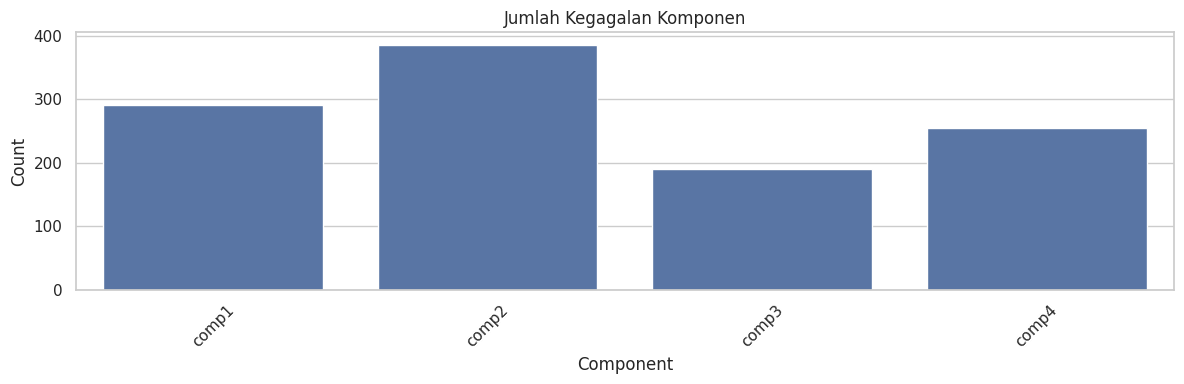

In [35]:
comp_fail_plot_df = (
    df.groupby('failure')
      .size()
      .reset_index(name='count')
)
comp_fail_plot_df_filtered = comp_fail_plot_df[comp_fail_plot_df['failure'] != 'none'].copy()

plt.figure(figsize=(12,4))
sns.barplot(data=comp_fail_plot_df_filtered, x='failure', y='count')
plt.xticks(rotation=45)
plt.title("Jumlah Kegagalan Komponen")
plt.xlabel("Component")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Hitung Jumlah Jenis Error

Jumlah Setiap Jenis Error:


,errorID,count
0,error1,1013
1,error2,988
2,error3,838
3,error4,728
4,error5,357


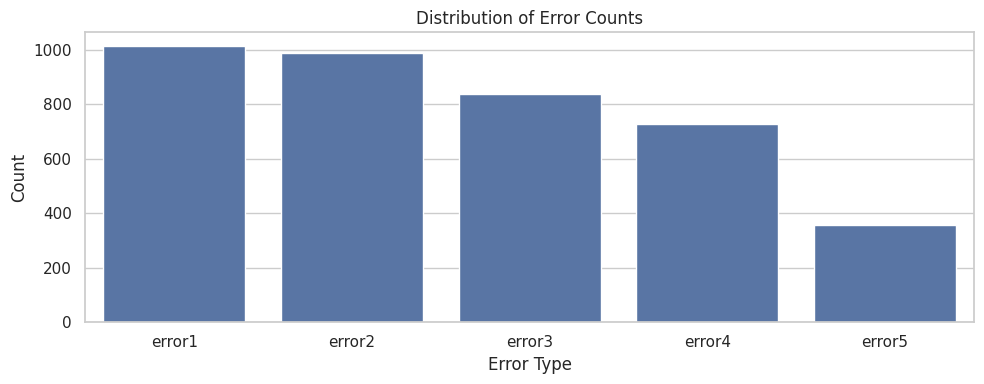

In [36]:
error_counts = (
    df[df['errorID'] != 'no_error']
    .groupby('errorID')
    .size()
    .reset_index(name='count')
)
print("Jumlah Setiap Jenis Error:")
display(error_counts)

plt.figure(figsize=(10,4))
sns.barplot(data=error_counts, x='errorID', y='count')
plt.title('Distribution of Error Counts')
plt.xlabel('Error Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

Jumlah Maintenance dari tiap komponen

Jumlah Maintenance per Komponen:


,comp,count
0,comp1,723
1,comp2,790
2,comp3,720
3,comp4,735


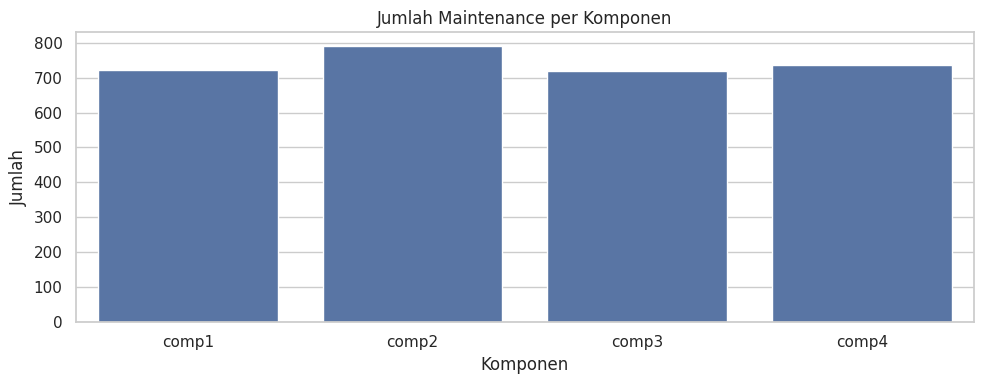

In [37]:
maintenance_counts = (
    df[df['comp'] != 'no_maintenance']
    .groupby('comp')
    .size()
    .reset_index(name='count')
)
print("Jumlah Maintenance per Komponen:")
display(maintenance_counts)

plt.figure(figsize=(10,4))
sns.barplot(data=maintenance_counts, x='comp', y='count')
plt.title('Jumlah Maintenance per Komponen')
plt.xlabel('Komponen')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()


Jumlah Kegagalan Dari Setiap Mesin


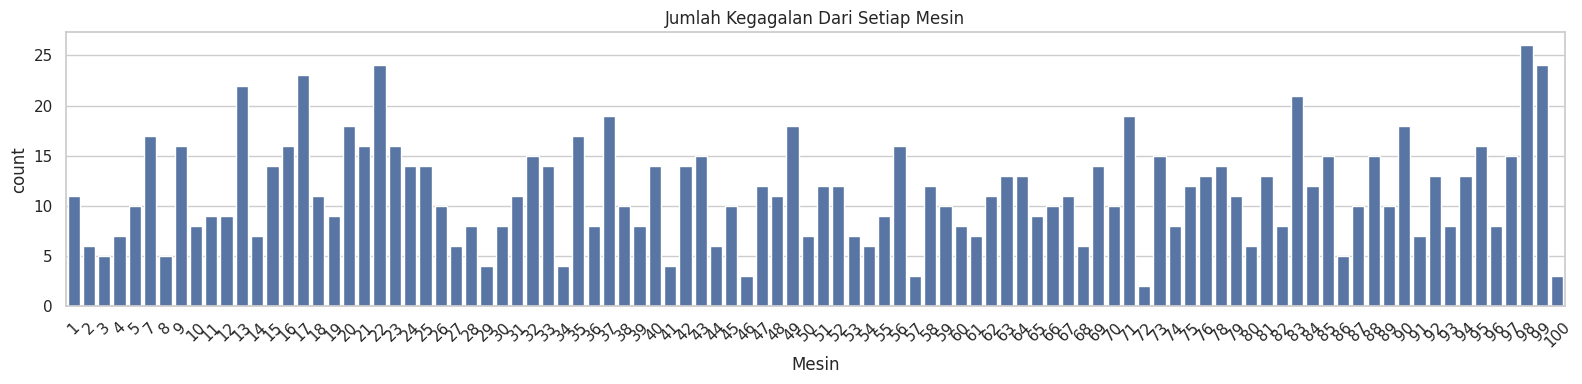

In [38]:
df_fail_pl = pl.from_pandas(df[df['failure'] != 'none'])

mach_fail_plot_df = (
    df_fail_pl
    .select(pl.col("machineID"))
    .group_by("machineID")
    .len()
    .sort("machineID")
).with_columns(
    percent = pl.col('len') / pl.col('len').sum() * 100
).rename({'len': 'count'})

plt.figure(figsize=(16,4))
sns.barplot(data=mach_fail_plot_df.to_pandas(), x='machineID', y='count')
plt.title("Jumlah Kegagalan Dari Setiap Mesin")
plt.xticks(rotation=45)
plt.xlabel("Mesin")
plt.tight_layout()
plt.show()


Hubungan Waktu terhadap Jumlah Kegagalan

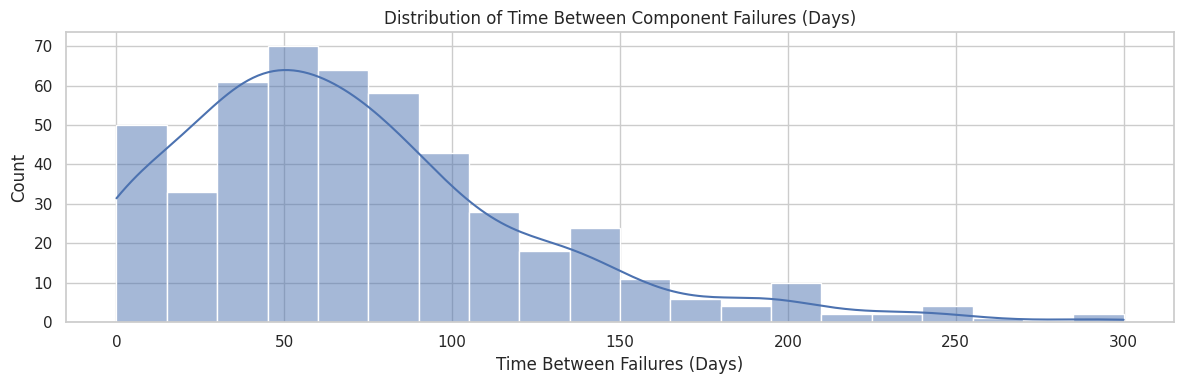

In [39]:
df['datetime'] = pd.to_datetime(df['datetime'])

df_pl = pl.from_pandas(df)
df_fail = df_pl.filter(pl.col("failure") != "none")

df_ranked = (
    df_fail
    .sort(["machineID", "comp", "datetime"])
    .with_columns(
        pl.int_range(0, pl.len()).over(["machineID", "comp"]).alias("failure_rank")
    )
)

df_after_first = df_ranked.filter(pl.col("failure_rank") > 0)

time_to_fail_df = (
    df_after_first
    .with_columns(
        pl.col("datetime")
        .shift(1)
        .over(["machineID", "comp"])
        .alias("prev_time")
    )
    .with_columns(
        (pl.col("datetime") - pl.col("prev_time"))
        .dt.total_days()
        .alias("time_between_failures")
    )
    .filter(pl.col("time_between_failures").is_not_null())
)

plt.figure(figsize=(12,4))
sns.histplot(
    time_to_fail_df.to_pandas(),
    x="time_between_failures",
    bins=20,
    kde=True
)
plt.title("Distribution of Time Between Component Failures (Days)")
plt.xlabel("Time Between Failures (Days)")
plt.tight_layout()
plt.show()

Eksplorasi Data Telemetry

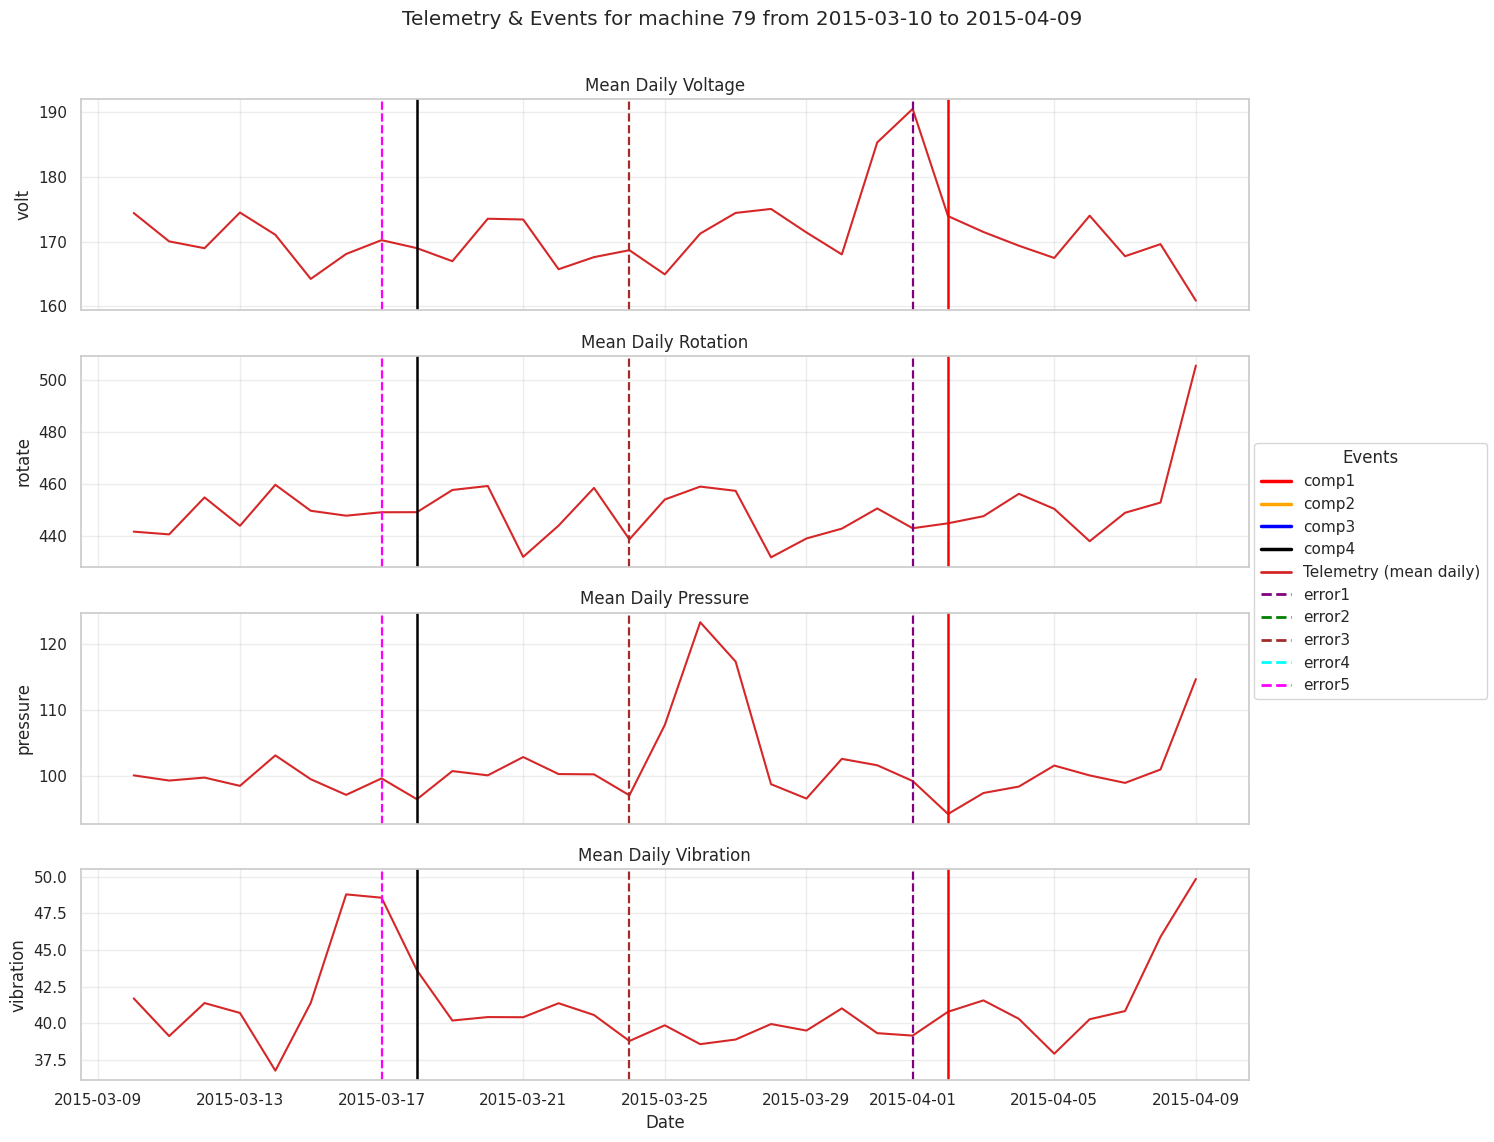

In [40]:
df_raw = df.copy()

df_sensor = df_raw.copy()
df_sensor['datetime'] = pd.to_datetime(df_sensor['datetime'])
df_sensor = df_sensor.sort_values('datetime')

machine_id = 79
start = datetime(2015, 3, 10)
end = start + timedelta(days=30)

df_machine = df_sensor[
    (df_sensor['machineID'] == machine_id) &
    (df_sensor['datetime'] >= start) &
    (df_sensor['datetime'] <= end)
].copy()

df_machine['date'] = df_machine['datetime'].dt.date

daily = (
    df_machine.groupby('date', as_index=False)
    .agg({
        'volt': 'mean',
        'rotate': 'mean',
        'pressure': 'mean',
        'vibration': 'mean',
        'failure': lambda x: x.where(x!='none').dropna().tolist(),
        'errorID': lambda x: x.where(x!='no_error').dropna().tolist(),
        'comp': lambda x: x.where(x!='no_maintenance').dropna().tolist(),
    })
)

daily['failure'] = daily['failure'].apply(lambda x: x[0] if len(x)>0 else 'none')
daily['errorID'] = daily['errorID'].apply(lambda x: x[0] if len(x)>0 else 'no_error')
daily['comp'] = daily['comp'].apply(lambda x: x[0] if len(x)>0 else 'no_maintenance')

failure_values = ['comp1','comp2','comp3','comp4']
error_values   = ['error1','error2','error3','error4','error5']

failure_dates = {fv: pd.to_datetime(daily[daily['failure']==fv]['date']).tolist()
                 for fv in failure_values}
error_dates = {ev: pd.to_datetime(daily[daily['errorID']==ev]['date']).tolist()
               for ev in error_values}

fig, axes = plt.subplots(4,1, figsize=(15,12), sharex=True)
sensor_cols = ['volt','rotate','pressure','vibration']
titles = ['Mean Daily Voltage','Mean Daily Rotation','Mean Daily Pressure','Mean Daily Vibration']
telemetry_color = 'tab:red'

failure_colors = ['red','orange','blue','black']
error_colors   = ['purple','green','brown','cyan','magenta']

for ax, col, title in zip(axes, sensor_cols, titles):
    sns.lineplot(data=daily, x='date', y=col, ax=ax, color=telemetry_color)
    ax.set_title(title)
    ax.grid(True, alpha=0.35)

    for idx, comp in enumerate(failure_values):
        for d in failure_dates.get(comp, []):
            ax.axvline(x=d, color=failure_colors[idx], linestyle='-', linewidth=1.8)

    for idx, err in enumerate(error_values):
        for d in error_dates.get(err, []):
            ax.axvline(x=d, color=error_colors[idx], linestyle='--', linewidth=1.6)

legend_elements = []

for idx, comp in enumerate(failure_values):
    legend_elements.append(Line2D([0],[0], color=failure_colors[idx], lw=2.5, linestyle='-', label=comp))

legend_elements.append(Line2D([0],[0], color=telemetry_color, lw=2, label='Telemetry (mean daily)'))

for idx, err in enumerate(error_values):
    legend_elements.append(Line2D([0],[0], color=error_colors[idx], lw=2, linestyle='--', label=err))

fig.legend(handles=legend_elements, loc='center right', title='Events', frameon=True)

plt.suptitle(f"Telemetry & Events for machine {machine_id} from {start.date()} to {end.date()}", y=0.95)
plt.xlabel('Date')
plt.tight_layout(rect=[0,0,0.85,0.94])
plt.show()

# Pre-processing data

In [41]:
df = df_raw.copy()

Memastikan dan menyortir berdasarkan waktu

In [42]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
invalid_time = df['datetime'].isna().sum()
print(f"Jumlah baris dengan datetime tidak valid: {invalid_time}")

df = df.dropna(subset=['datetime'])
df = df.sort_values(['machineID','datetime']).reset_index(drop=True)
print("Proses penyortiran berdasarkan waktu selesai.")


Jumlah baris dengan datetime tidak valid: 0
Proses penyortiran berdasarkan waktu selesai.


Normalisasi Teks Event

In [43]:
for col in ['failure', 'errorID', 'comp']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.lower().str.strip()
        df[col] = df[col].replace(['nan','null',''], 'none')

print("\nNilai unik kolom failure (setelah cleaning):")
print(df['failure'].unique())



Nilai unik kolom failure (setelah cleaning):
['none' 'comp4' 'comp1' 'comp2' 'comp3']


Interpolasi Missing Value

In [44]:
telemetry_cols = ['volt', 'rotate', 'pressure', 'vibration']

missing_before = df[telemetry_cols].isna().sum()
df[telemetry_cols] = df[telemetry_cols].interpolate(method='linear')
missing_after = df[telemetry_cols].isna().sum()
filled_values = missing_before - missing_after

print("\nJumlah missing value sebelum interpolasi:\n", missing_before)
print("\nJumlah missing value setelah interpolasi:\n", missing_after)
print("\nJumlah missing value yang berhasil diisi:\n", filled_values)


Jumlah missing value sebelum interpolasi:
 volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

Jumlah missing value setelah interpolasi:
 volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

Jumlah missing value yang berhasil diisi:
 volt         0
rotate       0
pressure     0
vibration    0
dtype: int64


Feature engineering (Ekstraksi waktu)

In [45]:
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['day'] = df['datetime'].dt.day
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek
print("Proses ekstraksi fitur waktu selesai.")

Proses ekstraksi fitur waktu selesai.


Labeling numerik failure

In [46]:
df['failure_label'] = (df['failure'] != 'none').astype(int)
print("Label failure_label selesai dibuat.")

Label failure_label selesai dibuat.


Cek duplikasi

In [47]:
initial_len = len(df)
df = df.drop_duplicates()
print(f"\nJumlah baris duplikasi yang dihapus: {initial_len - len(df)}")


Jumlah baris duplikasi yang dihapus: 0


Menangani missing value terakhir

In [48]:
df = df.fillna({
    'failure': 'none',
    'errorID': 'none',
    'comp': 'none'
})

df_clean = df.copy()
print("\nShape dataframe setelah preprocessing:", df_clean.shape)
display(df_clean.head())


Shape dataframe setelah preprocessing: (877209, 17)


,datetime,machineID,volt,rotate,pressure,vibration,model,age,failure,errorID,comp,year,month,day,hour,day_of_week,failure_label
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,model3,18,none,no_error,no_maintenance,2015,1,1,6,3,0
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,model3,18,none,no_error,no_maintenance,2015,1,1,7,3,0
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,model3,18,none,no_error,no_maintenance,2015,1,1,8,3,0
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,model3,18,none,no_error,no_maintenance,2015,1,1,9,3,0
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,model3,18,none,no_error,no_maintenance,2015,1,1,10,3,0


# EDA setelah Pre-processing

Overview datasets

In [49]:
print("Jumlah baris:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))
print("\nNama kolom:\n", df_clean.columns.tolist())

print("\nInformasi dataset:")
df_clean.info()

print("\nStatistik deskriptif telemetry:")
display(df_clean[telemetry_cols].describe())


Jumlah baris: 877209
Jumlah kolom: 17

Nama kolom:
 ['datetime', 'machineID', 'volt', 'rotate', 'pressure', 'vibration', 'model', 'age', 'failure', 'errorID', 'comp', 'year', 'month', 'day', 'hour', 'day_of_week', 'failure_label']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 877209 entries, 0 to 877208
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   datetime       877209 non-null  datetime64[ns]
 1   machineID      877209 non-null  int64         
 2   volt           877209 non-null  float64       
 3   rotate         877209 non-null  float64       
 4   pressure       877209 non-null  float64       
 5   vibration      877209 non-null  float64       
 6   model          877209 non-null  object        
 7   age            877209 non-null  int64         
 8   failure        877209 non-null  object        
 9   errorID        877209 non-null  object        
 10  comp     

,volt,rotate,pressure,vibration
count,877209.000000,877209.000000,877209.000000,877209.000000
mean,170.780942,446.570735,100.861433,40.386459
std,15.511268,52.698963,11.052195,5.371894
min,97.333604,138.432075,51.237106,14.877054
25%,160.305918,412.265479,93.499116,36.777911
50%,170.609301,447.537538,100.426820,40.238339
75%,181.008303,482.157025,107.557338,43.786484
max,255.124717,695.020984,185.951998,76.791072


Distribusi Telemetry

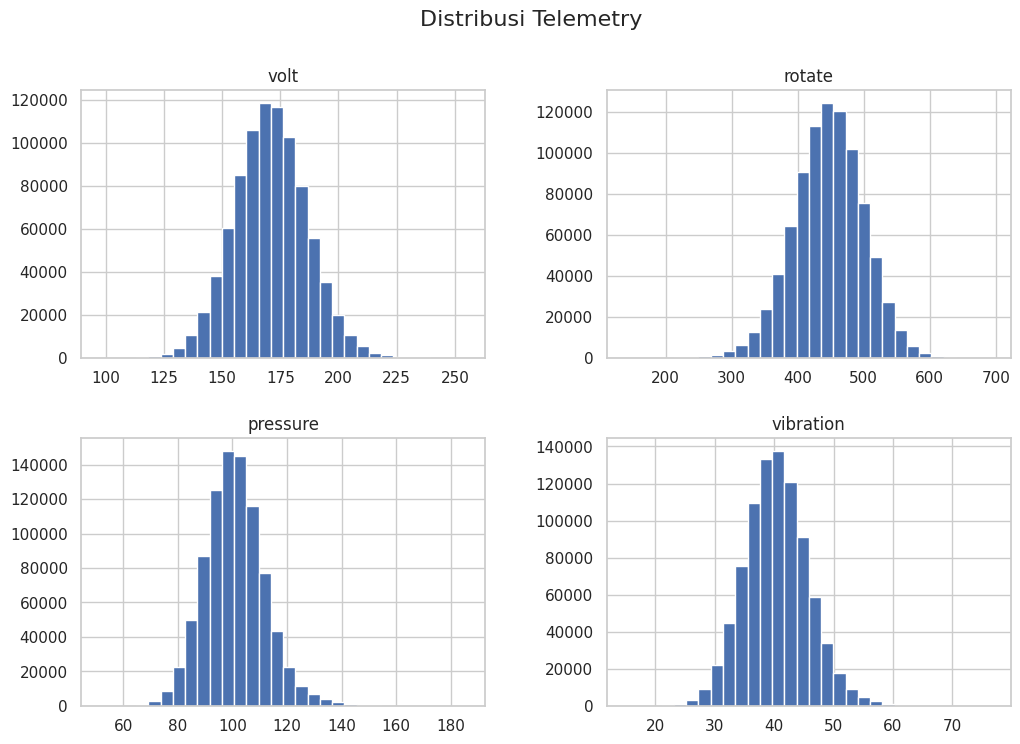

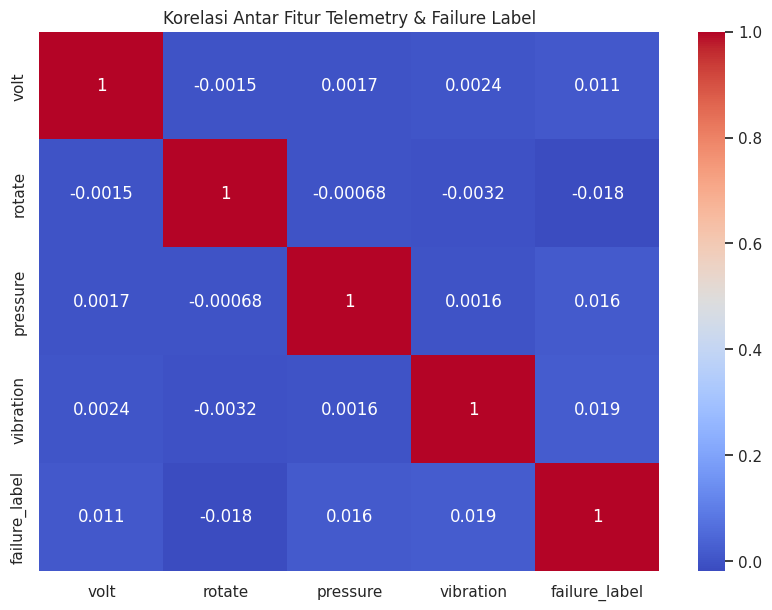

In [50]:
df_clean[telemetry_cols].hist(figsize=(12,8), bins=30)
plt.suptitle("Distribusi Telemetry", fontsize=16)
plt.show()

# Korelasi antar fitur + label
plt.figure(figsize=(10,7))
sns.heatmap(
    df_clean[['volt','rotate','pressure','vibration','failure_label']].corr(),
    annot=True, cmap="coolwarm"
)
plt.title("Korelasi Antar Fitur Telemetry & Failure Label")
plt.show()

BoxPlot Telemetry vs Failure

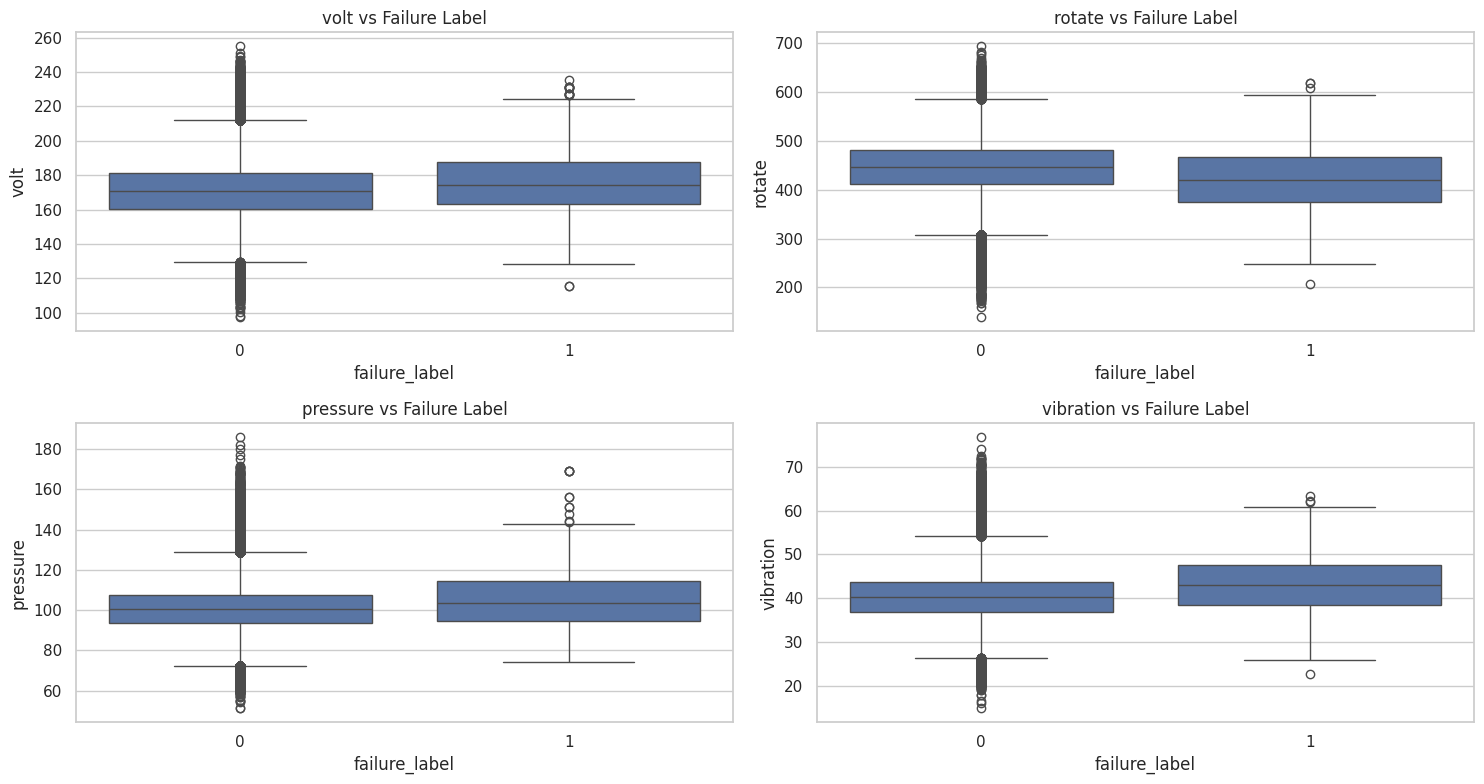

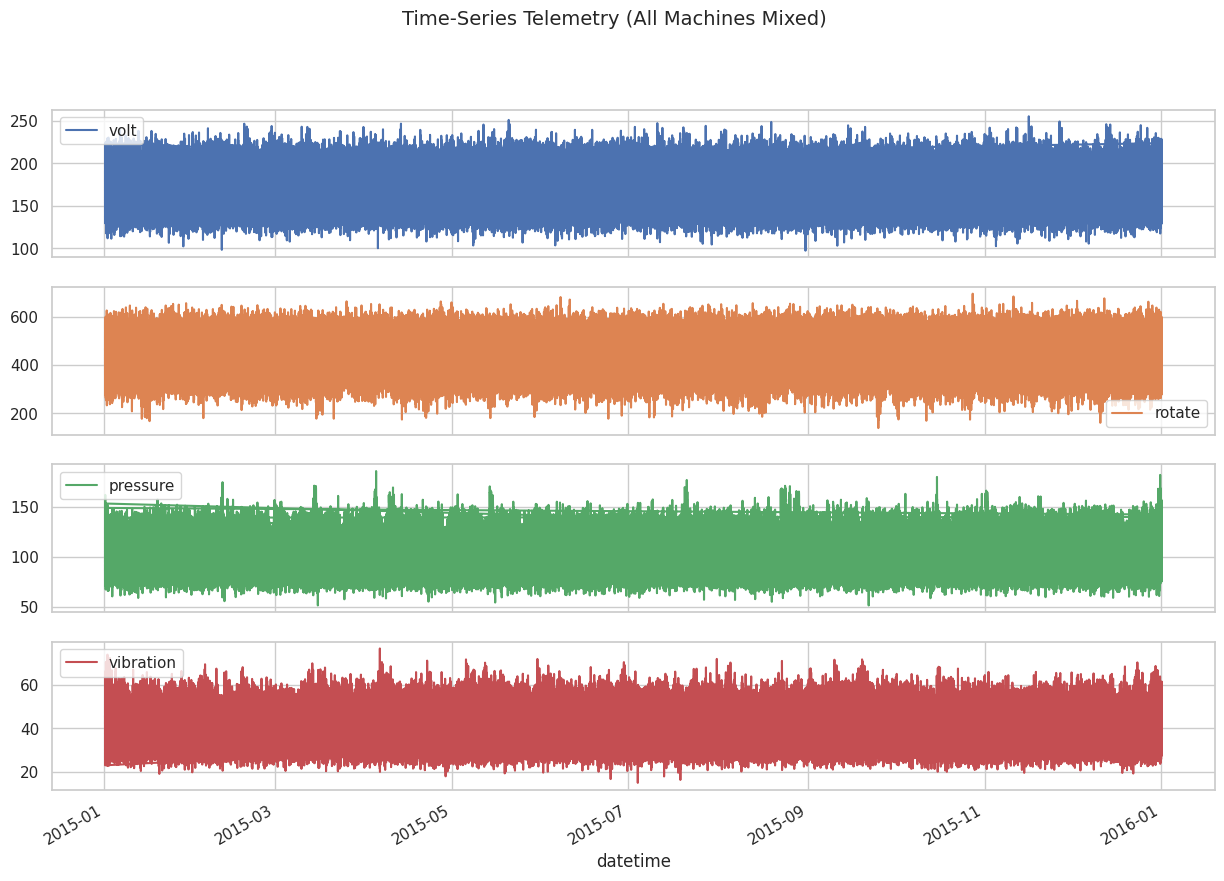

In [51]:
plt.figure(figsize=(15,8))
for i, col in enumerate(telemetry_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df_clean, x='failure_label', y=col)
    plt.title(f"{col} vs Failure Label")
plt.tight_layout()
plt.show()

# Time series plot (agregat)
df_ts = df_clean.set_index('datetime')
df_ts[telemetry_cols].plot(subplots=True, figsize=(15,10), sharex=True)
plt.suptitle("Time-Series Telemetry (All Machines Mixed)", fontsize=14)
plt.show()

# LSTM MODEL

In [68]:
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

# Functional API — input selalu terdefinisi
inputs = Input(shape=(sequence_length, len(telemetry_cols)), name="lstm_input")

x = LSTM(64, return_sequences=True)(inputs)
x = Dropout(0.2)(x)
x = LSTM(32)(x)

embedding = Dense(16, activation='relu', name="embedding_layer")(x)

outputs = Dense(1, activation='sigmoid', name="output")(embedding)

# Buat model LSTM
model_lstm = Model(inputs=inputs, outputs=outputs)

model_lstm.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_lstm.summary()


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_input (InputLayer)         │ (None, 30, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_layer (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

Train LSTM

In [69]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model_lstm.fit(
    X_lstm, y_lstm,
    validation_split=0.2,
    epochs=25,
    batch_size=64,
    callbacks=[early_stop]
)


Epoch 1/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 99s 9ms/step - accuracy: 0.9980 - loss: 0.0166 - val_accuracy: 0.9986 - val_loss: 0.0109
Epoch 2/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 95s 9ms/step - accuracy: 0.9989 - loss: 0.0090 - val_accuracy: 0.9986 - val_loss: 0.0109
Epoch 3/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 96s 9ms/step - accuracy: 0.9988 - loss: 0.0092 - val_accuracy: 0.9986 - val_loss: 0.0109
Epoch 4/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 96s 9ms/step - accuracy: 0.9988 - loss: 0.0094 - val_accuracy: 0.9986 - val_loss: 0.0109
Epoch 5/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 96s 9ms/step - accuracy: 0.9988 - loss: 0.0093 - val_accuracy: 0.9986 - val_loss: 0.0109
Epoch 6/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 96s 9ms/step - accuracy: 0.9988 - loss: 0.0092 - val_accuracy: 0.9986 - val_loss: 0.0109
Epoch 7/25
10929/10929 ━━━━━━━━━━━━━━━━━━━━ 96s 9ms/step - accuracy: 0.9987 - loss: 0.0097 - val_accuracy: 0.9986 - val_loss: 0.0112


In [70]:
# Ambil layer embedding berdasarkan nama
embedding_layer = model_lstm.get_layer("embedding_layer")

# Buat model embedding
embed_model = Model(
    inputs=model_lstm.input,
    outputs=embedding_layer.output
)

# Prediksi embedding
embeddings = embed_model.predict(X_lstm, verbose=0)

print("Embedding shape:", embeddings.shape)


Embedding shape: (874309, 16)


Tambahkan LSTM ke Df_Clean

In [71]:
df_clean['lstm_feat'] = 0.0

for idx, emb in zip(idx_end_global, embeddings):
    df_clean.at[idx, 'lstm_feat'] = emb[0]   # gunakan dimensi pertama


## Feature Engineering Lanjutan

In [72]:
df_fe = df_clean.copy()
df_fe['datetime'] = pd.to_datetime(df_fe['datetime'])
df_fe = df_fe.sort_values(['machineID','datetime'])
df_fe = df_fe.set_index(['machineID','datetime'])


Lag Features

In [73]:
for col in telemetry_cols:
    df_fe[f"{col}_lag1"] = df_fe.groupby("machineID")[col].shift(1)
    df_fe[f"{col}_lag3"] = df_fe.groupby("machineID")[col].shift(3)
    df_fe[f"{col}_lag6"] = df_fe.groupby("machineID")[col].shift(6)

print("Proses lag features selesai.")


Proses lag features selesai.


Rolling Statistics

In [74]:
windows = [3, 6, 12]
for col in telemetry_cols:
    grp = df_fe.groupby("machineID")[col]
    for w in windows:
        df_fe[f"{col}_roll_mean_{w}"] = grp.rolling(w).mean().reset_index(level=0, drop=True)
        df_fe[f"{col}_roll_std_{w}"]  = grp.rolling(w).std().reset_index(level=0, drop=True)
        df_fe[f"{col}_roll_max_{w}"]  = grp.rolling(w).max().reset_index(level=0, drop=True)
        df_fe[f"{col}_roll_min_{w}"]  = grp.rolling(w).min().reset_index(level=0, drop=True)

Trend Features

In [75]:
for col in telemetry_cols:
    df_fe[f"{col}_delta"] = df_fe.groupby("machineID")[col].diff()

print("Proses trend features selesai.")

Proses trend features selesai.


Error and Component Event Features

In [76]:
df_model = df_fe.reset_index()

# Label failure (pastikan konsisten)
df_model['failure_label'] = (df_model['failure'] != 'none').astype(int)

print("\nContoh df_model setelah feature engineering:")
display(df_model.head())



Contoh df_model setelah feature engineering:


,machineID,datetime,volt,rotate,pressure,vibration,model,age,failure,errorID,...,vibration_roll_max_6,vibration_roll_min_6,vibration_roll_mean_12,vibration_roll_std_12,vibration_roll_max_12,vibration_roll_min_12,volt_delta,rotate_delta,pressure_delta,vibration_delta
0,1,2015-01-01 06:00:00,176.217853,418.504078,113.077935,45.087686,model3,18,none,no_error,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2015-01-01 07:00:00,162.879223,402.747490,95.460525,43.413973,model3,18,none,no_error,...,NaN,NaN,NaN,NaN,NaN,NaN,-13.338630,-15.756589,-17.617410,-1.673713
2,1,2015-01-01 08:00:00,170.989902,527.349825,75.237905,34.178847,model3,18,none,no_error,...,NaN,NaN,NaN,NaN,NaN,NaN,8.110680,124.602336,-20.222621,-9.235126
3,1,2015-01-01 09:00:00,162.462833,346.149335,109.248561,41.122144,model3,18,none,no_error,...,NaN,NaN,NaN,NaN,NaN,NaN,-8.527069,-181.200490,34.010656,6.943297
4,1,2015-01-01 10:00:00,157.610021,435.376873,111.886648,25.990511,model3,18,none,no_error,...,NaN,NaN,NaN,NaN,NaN,NaN,-4.852812,89.227538,2.638087,-15.131633


#  Pemodelan XGBOOST

Siapkan Data

In [77]:
# Encode kategori
df_model[['errorID','comp']] = df_model[['errorID','comp']].astype(str)

# One-hot encoding
df_dummies = pd.get_dummies(df_model[['errorID','comp']], drop_first=True)

# Ambil hanya numeric yang relevan
numeric_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()

# Buang kolom label dari fitur
cols_to_exclude = ['failure_label']
numeric_feature_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# FINAL X & y
X = pd.concat([df_model[numeric_feature_cols], df_dummies], axis=1)
y = df_model['failure_label']

# Safety check
if X.select_dtypes(include=['object']).shape[1] > 0:
    print("Masih ada kolom non-numeric di X:")
    print(X.select_dtypes(include=['object']).columns)
    raise ValueError("Bersihkan X dari kolom non-numeric!")

print("Shape X:", X.shape)
print("Shape y:", y.shape)


Shape X: (877209, 85)
Shape y: (877209,)


Split Data

In [78]:
cutoff_date = pd.to_datetime("2015-08-01")

mask_train = df_model['datetime'] < cutoff_date
mask_test  = df_model['datetime'] >= cutoff_date

X_train, X_test = X[mask_train], X[mask_test]
y_train, y_test = y[mask_train], y[mask_test]

print("Jumlah data train:", X_train.shape[0])
print("Jumlah data test :", X_test.shape[0])


Jumlah data train: 508840
Jumlah data test : 368369


Training Model

In [79]:
# Tangani class imbalance
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos if pos > 0 else 1.0

print("Negatives:", neg, "Positives:", pos)
print("scale_pos_weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    tree_method="hist",
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred  = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:,1]

print("=== XGBoost Classification Report ===")
print(classification_report(y_test, xgb_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_proba))


Negatives: 508173 Positives: 667
scale_pos_weight: 761.8785607196402
=== XGBoost Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    367914
           1       0.84      1.00      0.91       455

    accuracy                           1.00    368369
   macro avg       0.92      1.00      0.96    368369
weighted avg       1.00      1.00      1.00    368369

Confusion Matrix:
[[367828     86]
 [     0    455]]
ROC-AUC: 0.9999456782990435


ROC

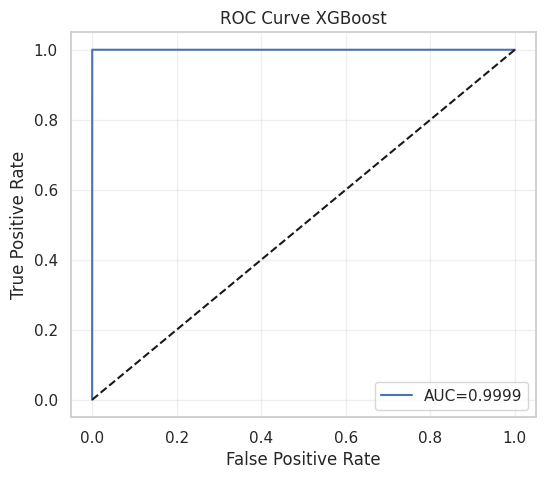

In [80]:
fpr, tpr, _ = roc_curve(y_test, xgb_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, xgb_proba):.4f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve XGBoost")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# SURVIVAL MODEL – WEIBULL (RUL BERDASARKAN TIME TO FAILURE)

Contoh survival dataset (Weibull):


,machineID,comp,time_to_fail,event
1539,1,comp1,60.0,1
4061,1,comp1,105.0,1
5862,1,comp1,75.0,1
6946,1,comp2,180.0,1
4062,1,comp4,165.0,1


<lifelines.WeibullFitter:"Weibull-RUL", fitted with 763 total observations, 0 right-censored observations>
   number of observations = 763
number of events observed = 763
           log-likelihood = -3721.66
               hypothesis = lambda_ != 1, rho_ != 1

---
         coef  se(coef)  coef lower 95%  coef upper 95%
lambda_ 59.30      4.70           50.09           68.51
rho_     0.46      0.02            0.43            0.49

         cmp to      z      p  -log2(p)
lambda_    1.00  12.41 <0.005    115.06
rho_       1.00 -33.53 <0.005    816.36
---
AIC = 7447.31

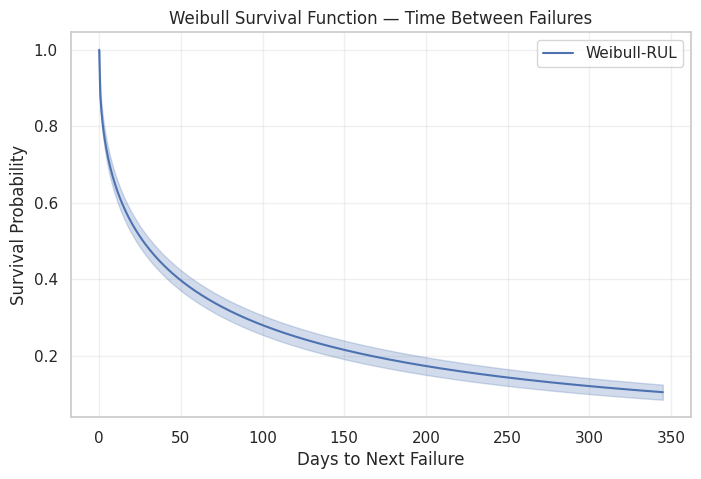

In [81]:
df_rul = df_clean.copy()
df_rul['datetime'] = pd.to_datetime(df_rul['datetime'])
df_rul = df_rul.sort_values(['machineID', 'datetime'])

# Ambil hanya baris yang mengalami failure
df_fail = df_rul[df_rul['failure'] != 'none'].copy()
df_fail = df_fail.sort_values(['machineID', 'comp', 'datetime'])

df_fail['prev_datetime'] = df_fail.groupby(['machineID','comp'])['datetime'].shift(1)
df_fail['time_to_fail']  = (df_fail['datetime'] - df_fail['prev_datetime']).dt.total_seconds() / 86400
df_fail = df_fail.dropna(subset=['time_to_fail'])

# Pastikan > 0
df_fail['time_to_fail'] = df_fail['time_to_fail'].apply(lambda x: x if x>0 else 1e-6)
df_fail['event'] = 1

surv_data = df_fail[['machineID','comp','time_to_fail','event']]
print("Contoh survival dataset (Weibull):")
display(surv_data.head())

wf = WeibullFitter()
wf.fit(
    durations      = surv_data['time_to_fail'],
    event_observed = surv_data['event'],
    label          = "Weibull-RUL"
)

wf.print_summary()

plt.figure(figsize=(8,5))
wf.plot_survival_function()
plt.title("Weibull Survival Function — Time Between Failures")
plt.xlabel("Days to Next Failure")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()


# Survival Model – CoxPH Harian + LSTM Score

Agregasi Harian + LSTM Score

In [82]:
df_daily = (
    df_clean
    .assign(date = df_clean['datetime'].dt.floor('D'))
    .groupby(['machineID','date'], as_index=False)
    .agg({
        'volt'     : 'mean',
        'rotate'   : 'mean',
        'pressure' : 'mean',
        'vibration': 'mean',
        'lstm_feat': 'mean',
        'failure'  : lambda x: (x != 'none').any()
    })
)

df_daily['event'] = df_daily['failure'].astype(int)
df_daily = df_daily.drop(columns=['failure'])
df_daily = df_daily.sort_values(['machineID','date']).reset_index(drop=True)

# Durasi = hari ke-n (sejak awal rekaman per mesin)
df_daily['duration'] = df_daily.groupby('machineID').cumcount()

print("Contoh df_daily:")
display(df_daily.head())


Contoh df_daily:


,machineID,date,volt,rotate,pressure,vibration,lstm_feat,event,duration
0,1,2015-01-01,167.576533,440.515328,98.522345,40.049623,0.000000,0,0
1,1,2015-01-02,169.795758,446.832666,98.454608,39.271645,2.173746,0,1
2,1,2015-01-03,171.862244,459.204742,97.998233,48.074091,4.013069,0,2
3,1,2015-01-04,174.792428,448.743201,101.452266,52.190268,4.013068,0,3
4,1,2015-01-05,171.349797,456.620958,102.741911,43.692423,4.013069,1,4


Fit CoxPH dan Prediksi RUL

=== CoxPH Summary ===


<lifelines.CoxPHFitter: fitted with 36600 total observations, 35882 right-censored observations>
             duration col = 'duration'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 36600
number of events observed = 718
   partial log-likelihood = -6734.68
         time fit was run = 2025-12-10 00:31:43 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
lstm_feat -13.29      0.00     22.99          -58.36           31.78                0.00            6.35e+13
volt        0.01      1.01      0.01           -0.01            0.02                0.99                1.02
rotate     -0.00      1.00      0.00           -0.01            0.00                0.99                1.00
pressure    0.00      1.00      0.01           -0.01            0.02                0.99                1.02
vibration   0.02      1.02      0.02           -0.02            0.05                0.98                1.05

           cmp to     z    p  -log2(p)
covariate                             
lstm_feat    0.00 -0.58 0.56      0.83
volt         0.00  0.81 0.42      1.25
rotate       0.00 -1.08 0.28      1.84
pressure     0.00  0.67 0.50      0.99
vibration    0.00  0.99 0.32      1.64
---
Concordance = 0.74
Partial AIC = 13479.35
log-likelihood ratio test = 270.13 on 5 df
-log2(p) of ll-ratio test = 184.64

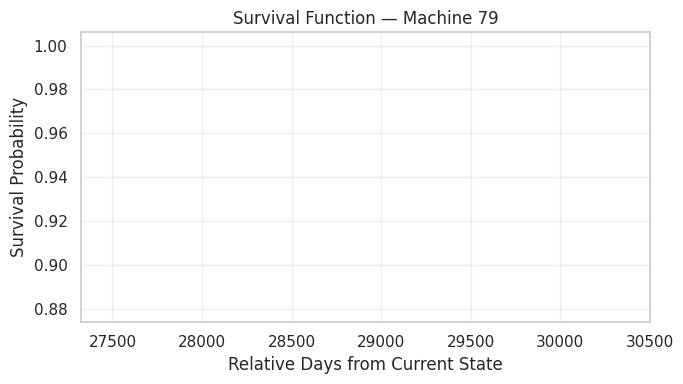

Survival tidak turun sampai 0.5 untuk mesin 79 — mesin masih relatif sehat.


In [86]:
tele_cols_daily = ['volt','rotate','pressure','vibration']
covariates = ['duration','event','lstm_feat'] + tele_cols_daily

df_surv = df_daily[covariates].copy()

cph = CoxPHFitter()
cph.fit(
    df_surv,
    duration_col='duration',
    event_col='event'
)

print("=== CoxPH Summary ===")
cph.print_summary()

# Ambil satu mesin contoh
example_mid = 79
df_m = df_daily[df_daily['machineID'] == example_mid].copy()
df_m = df_m.sort_values('duration')

if not df_m.empty:
    last_state = df_m.iloc[[-1]][['duration','lstm_feat', *tele_cols_daily]]
    surv_func  = cph.predict_survival_function(last_state)

    plt.figure(figsize=(7,4))
    plt.plot(surv_func.T)
    plt.title(f"Survival Function — Machine {example_mid}")
    plt.xlabel("Relative Days from Current State")
    plt.ylabel("Survival Probability")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    vals = surv_func.iloc[:,0].values
    idx  = np.where(vals < 0.5)[0]
    if len(idx) > 0:
        rul_days = idx[0]
        print(f"Estimated RUL (S(t)<0.5) untuk mesin {example_mid}: {rul_days} hari")
    else:
        print(f"Survival tidak turun sampai 0.5 untuk mesin {example_mid} — mesin masih relatif sehat.")
else:
    print(f"Tidak ada data harian untuk machineID {example_mid}.")


# Deployment

LSTM TO TFJS

In [87]:
!pip install tensorflowjs


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 4.8 MB/s eta 0:00:00
  Attempting uninstall: packaging
    Found existing installation: packaging 25.0
    Uninstalling packaging-25.0:
      Successfully uninstalled packaging-25.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.38.0 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
xarray 2025.11.0 requires packaging>=24.1, but you have packaging 23.2 which is incompatible.
db-dtypes 1.4.4 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.


In [88]:
model_lstm.save("lstm_model.h5")
embed_model.save("embedding_model.h5")


In [90]:
!tensorflowjs_converter --input_format=keras --quantization_bytes=1 lstm_model.h5 lstm_tfjs/

2025-12-10 00:53:55.422627: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765328035.458468   45542 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765328035.468583   45542 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1765328035.506311   45542 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1765328035.508543   45542 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1765328035.508570   45542 computation_placer.cc:177] computation placer alr

In [91]:
!zip -r lstm_tfjs.zip lstm_tfjs/


  adding: lstm_tfjs/ (stored 0%)
  adding: lstm_tfjs/model.json (deflated 81%)
  adding: lstm_tfjs/group1-shard1of1.bin (deflated 7%)


XGBoost rest API

In [101]:
import joblib
joblib.dump(xgb_model, "xgb.pkl")

['xgb.pkl']

Survival Model

In [105]:
import joblib
joblib.dump(wf, "weibull_rul.pkl")
print("Weibull model saved!")

Weibull model saved!


load

In [110]:
import joblib
wf = joblib.load("weibull_rul.pkl")

Exort COXPH MODEL

In [108]:
import joblib
joblib.dump(cph, "coxph_rul.pkl")
print("CoxPH RUL saved!")

CoxPH RUL saved!


load

In [111]:
import joblib
cph = joblib.load("coxph_rul.pkl")

API BACKEND UNTUK SURVIVAL MODEL (FAST API)

In [112]:
from fastapi import FastAPI
import pandas as pd
from lifelines import CoxPHFitter, WeibullFitter
import joblib

app = FastAPI()

cph = joblib.load("coxph_rul.pkl")
wf = joblib.load("weibull_rul.pkl")

@app.post("/predict_rul")
def predict_rul(payload: dict):
    df = pd.DataFrame([payload])
    surv = cph.predict_survival_function(df)
    prob = surv.iloc[:,0].values

    # cari waktu survival < 0.5
    idx = (prob < 0.5).argmax()
    rul = int(idx)

    return {"rul_days": rul}

# CARA INTEGRASI DI WEB

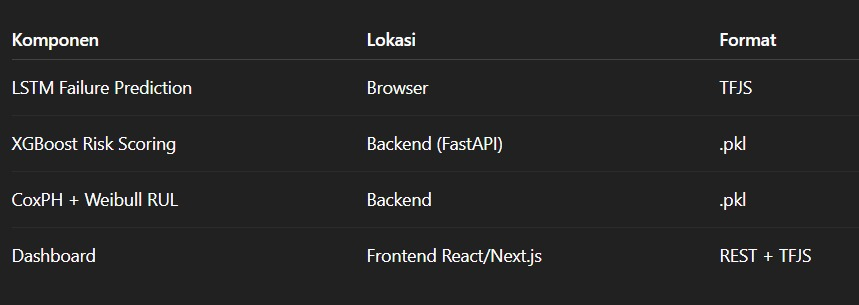